In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

In [3]:
data = pd.read_csv("/content/Wholesale customers data.csv")
print("Dataset loaded successfully")
data.head()

Dataset loaded successfully


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [4]:
data.shape

(440, 8)

In [5]:
data.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [7]:
data.isnull().sum()

,0
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


In [18]:
# Select the six annual-spending columns as clustering features.
features = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
X= data[features]
print("Features selected for clustering:", features)

Features selected for clustering: ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']


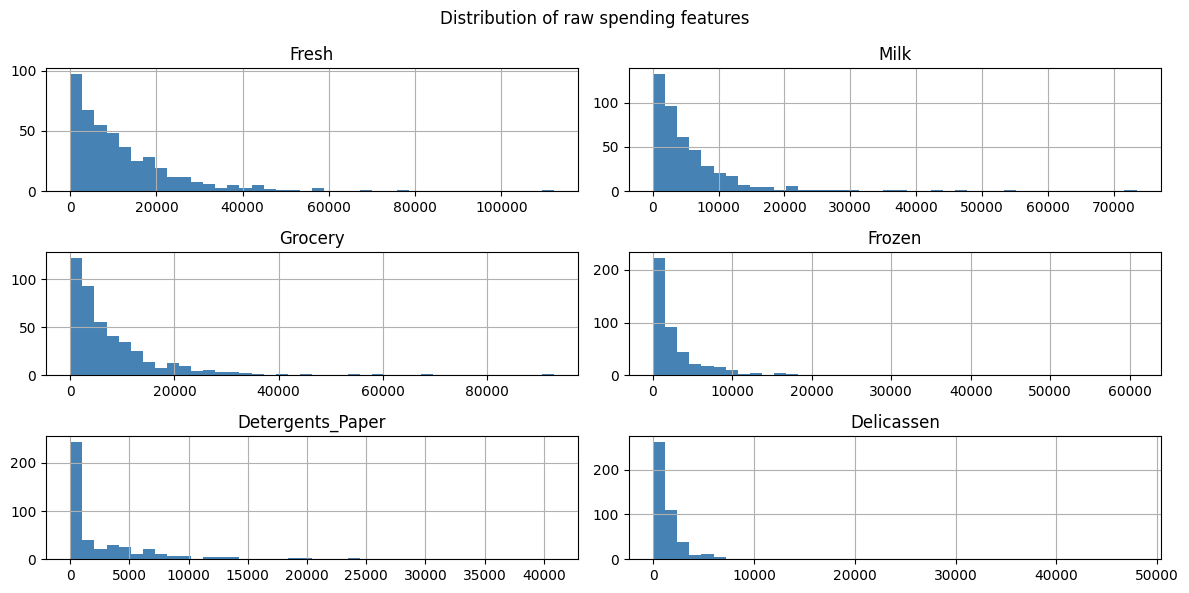

In [17]:
# Visualize the skew of the raw features
X.hist(bins=40, figsize=(12,6), color='steelblue')
plt.suptitle("Distribution of raw spending features")
plt.tight_layout()
plt.show()

In [19]:
# Apply StandardScaler to normalize the selected features=
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Feature scaling complete using StandardScaler")

Feature scaling complete using StandardScaler


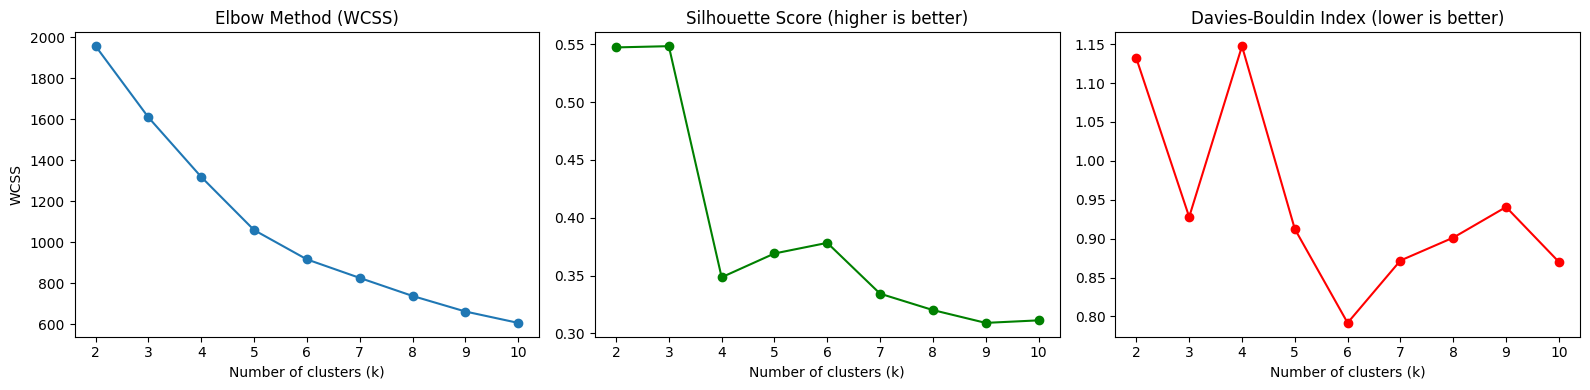

,k,WCSS,Silhouette,Davies-Bouldin
0,2,1956.12,0.5472,1.1318
1,3,1608.43,0.5483,0.9279
2,4,1317.84,0.3485,1.1475
3,5,1058.77,0.3690,0.9125
4,6,915.74,0.3782,0.7918
5,7,825.40,0.3343,0.8719
6,8,737.39,0.3201,0.9014
7,9,661.45,0.3090,0.9407
8,10,605.92,0.3112,0.8702


In [20]:
ks = range(2, 11)
wcss_list, sil_list, db_list = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    wcss_list.append(km.inertia_)
    sil_list.append(silhouette_score(X_scaled, km.labels_))
    db_list.append(davies_bouldin_score(X_scaled, km.labels_))

fig, axes = plt.subplots(1, 3, figsize=(16,4))
axes[0].plot(ks, wcss_list, marker='o'); axes[0].set_title('Elbow Method (WCSS)'); axes[0].set_ylabel('WCSS')
axes[1].plot(ks, sil_list, marker='o', color='green'); axes[1].set_title('Silhouette Score (higher is better)')
axes[2].plot(ks, db_list, marker='o', color='red'); axes[2].set_title('Davies-Bouldin Index (lower is better)')
for a in axes: a.set_xlabel('Number of clusters (k)')
plt.tight_layout()
plt.show()
pd.DataFrame({'k': list(ks), 'WCSS': np.round(wcss_list,2), 'Silhouette': np.round(sil_list,4), 'Davies-Bouldin': np.round(db_list,4)})

In [21]:
# Initialize the K-Means algorithm with 3 clusters and train it on the scaled features
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X_scaled)
print("Model trained successfully")

Model trained successfully


In [22]:
# Assign cluster labels to the original dataset and display the first 5 rows with cluster numbers
labels = kmeans.labels_
data['Cluster'] = labels
print("Cluster sizes:")
print(data['Cluster'].value_counts().sort_index())
data[features + ['Cluster']].head()

Cluster sizes:
Cluster
0     45
1    393
2      2
Name: count, dtype: int64


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Cluster
0,12669,9656,7561,214,2674,1338,1
1,7057,9810,9568,1762,3293,1776,1
2,6353,8808,7684,2405,3516,7844,1
3,13265,1196,4221,6404,507,1788,1
4,22615,5410,7198,3915,1777,5185,1


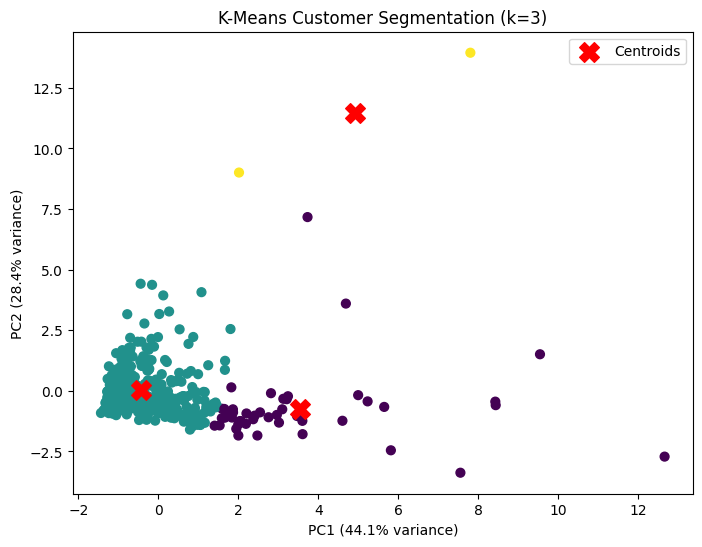

In [25]:
# Visualize the clusters in 2D using PCA, with centroids
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
centers_pca = pca.transform(kmeans.cluster_centers_)

plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=labels, cmap='viridis', s=40)
plt.scatter(centers_pca[:,0], centers_pca[:,1], c='red', s=200, marker='X', label='Centroids')
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("K-Means Customer Segmentation (k=3)")
plt.legend()
plt.show()

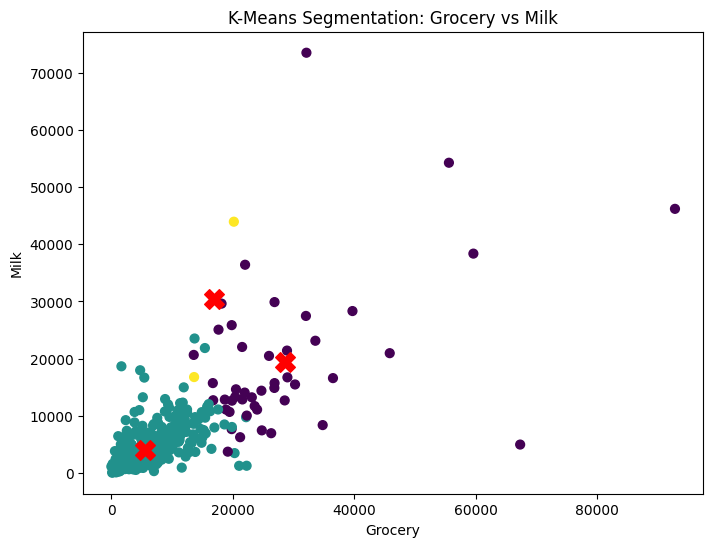

In [26]:
# Two-feature view similar to the reference notebook: Grocery vs Milk with centroids in original units
centers = scaler.inverse_transform(kmeans.cluster_centers_)
gi, mi = features.index('Grocery'), features.index('Milk')
plt.figure(figsize=(8,6))
plt.scatter(X['Grocery'], X['Milk'], c=labels, cmap='viridis', s=40)
plt.scatter(centers[:,gi], centers[:,mi], c='red', s=200, marker='X')
plt.xlabel("Grocery"); plt.ylabel("Milk")
plt.title("K-Means Segmentation: Grocery vs Milk")
plt.show()

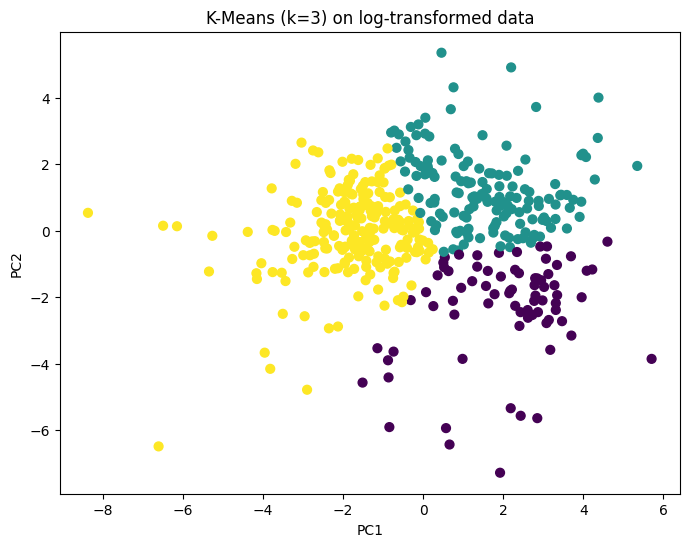

Channel,Horeca,Retail
row_0,,
0,28,47
1,57,92
2,213,3


In [30]:
# Define the log-transformed features
X_log = np.log(X)

# Train K-Means on log-transformed data
km_log = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_log)
Xp = PCA(n_components=2, random_state=42).fit_transform(X_log)

# Visualize
plt.figure(figsize=(8,6))
plt.scatter(Xp[:,0], Xp[:,1], c=km_log.labels_, cmap='viridis', s=40)
plt.title("K-Means (k=3) on log-transformed data"); plt.xlabel("PC1"); plt.ylabel("PC2")
plt.show()

# Cross-tabulate with the Channel column
pd.crosstab(km_log.labels_, data['Channel'].map({1:'Horeca', 2:'Retail'}))

In [27]:
# Calculate and display model evaluation metrics: Silhouette Score, WCSS (Inertia), Davies-Bouldin Index
score = silhouette_score(X_scaled, labels)
print("Silhouette Score:", score)
wcss = kmeans.inertia_
print("WCSS (Inertia):", wcss)
db_score = davies_bouldin_score(X_scaled, labels)
print("Davies-Bouldin Index:", db_score)

Silhouette Score: 0.5482872649700601
WCSS (Inertia): 1608.4311488289443
Davies-Bouldin Index: 0.9279350629308419
